# 02 – Frequency Characterization of Plant AE (0–100 kHz)

> **Historical dataset note:** This notebook documents the passive 2026-06-22 setup; it does not describe the active Pico sweep wiring from 2026-06-29 (CH1=GP14 marker, CH3/CH4=calibrated Stahl+LM358+830 kΩ probe heads).

**Dataset:** `data/long_captures/20260622_163645/raw` — 20 captures per channel,
500 kSa/s, 300 000 points, 0.6 s window, **1.67 Hz** frequency resolution,
Nyquist 250 kHz.

This notebook is the **reproducible documentation** of the
frequency characterization. It calls exclusively the validated functions from
`frequency_analysis.py` — the same ones that generate the report under
`data/reports/frequency_analysis_baseline_20260622/`. This guarantees
notebook and report are consistent (single implementation).

A spectral peak is accepted as a **candidate** only if it meets *all* three
criteria:

1. **Repeatability** ≥ 40 % of captures per channel,
2. **cross-channel coherence** (±1 kHz on ≥ 2 channels),
3. **SNR** ≥ 5 dB above the per-channel median noise floor.

Peaks that coincide with a resonance of the sensor chain (impulse response,
free ring-down) are additionally marked as **sensor resonance**.

> **Scientific context:** This is a *passive* measurement.
> Cross-channel coherence rules out sensor-specific artefacts, but
> **not** common-mode coupling. Sharp, persistent tones present on all
> channels are the signature of common-mode coupling, not of local plant AE.
> From this baseline measurement **no** peak can be attributed to the plant
> (see Section 8).

---

## References

Full source list: [`../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md`](../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md)

Key references for this notebook:
- Khait et al. (2023): airborne plant AE detection — defines the frequency range of plant acoustic events
- De Roo et al. (2016): xylem cavitation acoustic emissions — baseline for expected spectral signatures
- Zweifel & Zeugin (2008): drought-induced xylem cavitation in stems — relevant to sub-100 kHz signal morphology
- Oletic et al. (2020): low-power AE detection hardware — sensor and amplifier design context


## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# frequency_analysis.py lives in the characterization root; add path
from plant_ae.watering import CHARACTERIZATION_ROOT
if str(CHARACTERIZATION_ROOT) not in sys.path:
    sys.path.insert(0, str(CHARACTERIZATION_ROOT))
import frequency_analysis as fa
# %matplotlib inline AFTER fa import (fa otherwise forces the Agg backend)
%matplotlib inline

DATA_DIR = CHARACTERIZATION_ROOT / "data" / "long_captures" / "20260622_163645" / "raw"
IMPULSE_DIR = fa.IMPULSE_RAW_DIR
OUTPUT_DIR = CHARACTERIZATION_ROOT / "data" / "reports" / "notebooks" / "02_frequency_characterization"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHANNEL_LABELS = {1: "CH1 (Piezo + LM358, 10:1)",
                  2: "CH2 (Piezo + 820 kΩ, 1:1)",
                  3: "CH3 (Piezo direkt, 1:1)"}
CHANNEL_COLORS = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print("Validation criteria (from frequency_analysis.py):")
print(f"  Repeatability     >= {fa.REPEAT_MIN_FRACTION:.0%}")
print(f"  Coherence tolerance = +/- {fa.CROSS_CH_TOLERANCE_HZ/1e3:.1f} kHz, >= 2 channels")
print(f"  Minimum SNR         = {fa.MIN_SNR_DB:.0f} dB")
print(f"  Data directory      : {DATA_DIR.relative_to(CHARACTERIZATION_ROOT)}")

Validierungskriterien (aus frequency_analysis.py):
  Wiederholbarkeit  >= 40%
  Kohärenz-Toleranz  = +/- 1.0 kHz, >= 2 Kanäle
  Mindest-SNR        = 5 dB
  Datenverzeichnis   : data/long_captures/20260622_163645/raw


## 2. Load and average captures

For each channel all captures are loaded, the averaged PSD (periodogram,
Hann window, V²/Hz) is computed, and the repeatability analysis is performed.


In [2]:
channels_data = {}
rows = []
for ch in fa.CHANNELS:
    caps = fa.load_channel_captures(DATA_DIR, ch)
    if not caps:
        print(f"  WARNING: no captures for CH{ch}")
        continue
    first = sorted(DATA_DIR.glob(f"*_ch{ch}.npz"))[0]
    _, rate = fa.load_npz_capture(first)
    freqs, mean_psd, std_psd = fa.average_psd(caps, rate)
    channels_data[ch] = {
        "captures": caps, "freqs": freqs, "mean_psd": mean_psd,
        "std_psd": std_psd, "sample_rate_hz": rate,
        "repeatability": fa.check_repeatability(caps, rate),
    }
    df_res = rate / len(caps[0])
    rows.append({"Channel": CHANNEL_LABELS[ch], "Captures": len(caps),
                 "Sa/s": f"{rate/1e3:.0f}k", "Punkte": len(caps[0]),
                 "Window [s]": round(len(caps[0])/rate, 3),
                 "Δf [Hz]": round(df_res, 2)})

pd.DataFrame(rows)

,Kanal,Aufnahmen,Sa/s,Punkte,Fenster [s],Δf [Hz]
0,"CH1 (Piezo + LM358, 10:1)",20,500k,300000,0.6,1.67
1,"CH2 (Piezo + 820 kΩ, 1:1)",20,500k,300000,0.6,1.67
2,"CH3 (Piezo direkt, 1:1)",20,500k,300000,0.6,1.67


## 3. Time domain (oscilloscope view)

One representative single capture per channel — as recorded by the Rigol.


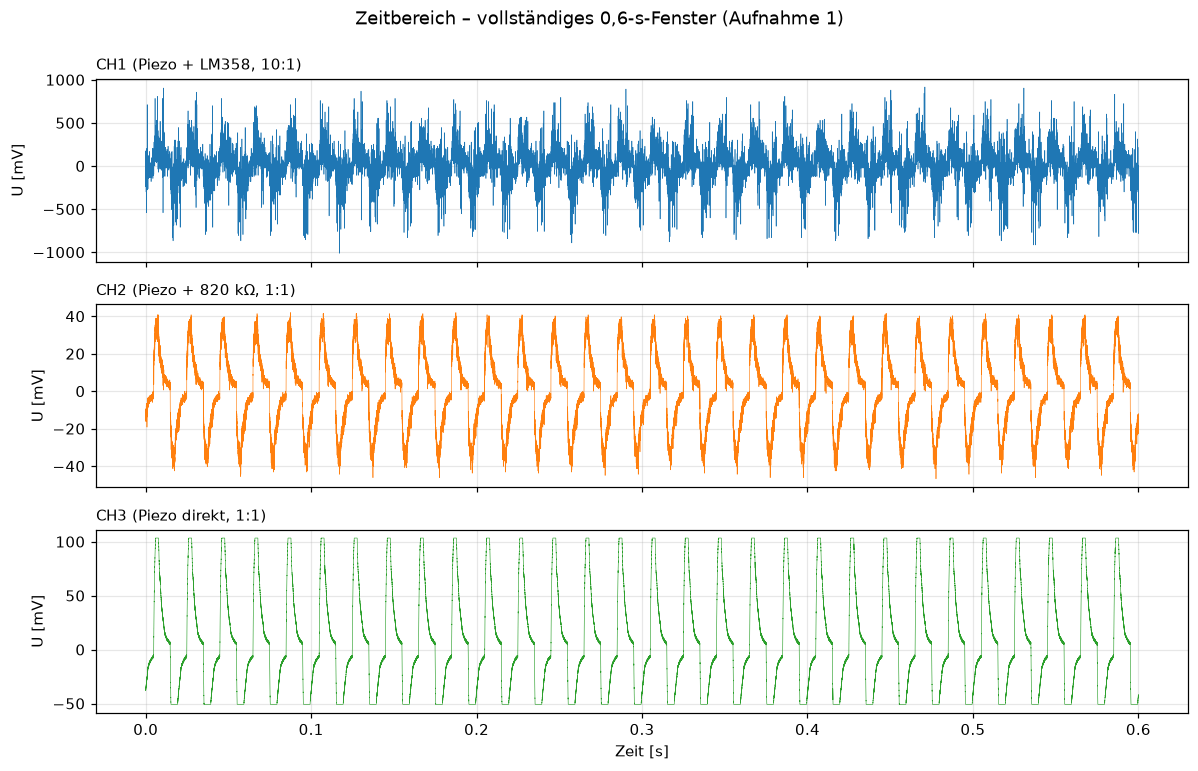

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, ch in zip(axes, fa.CHANNELS):
    v = channels_data[ch]["captures"][0]
    rate = channels_data[ch]["sample_rate_hz"]
    t = np.arange(len(v)) / rate
    ax.plot(t, v * 1e3, color=CHANNEL_COLORS[ch], lw=0.4)
    ax.set_ylabel("U [mV]")
    ax.set_title(CHANNEL_LABELS[ch], loc="left", fontsize=10)
axes[-1].set_xlabel("Time [s]")
fig.suptitle("Time domain – full 0.6 s window (capture 1)", y=0.995)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "timeseries_full.png", bbox_inches="tight")
plt.show()

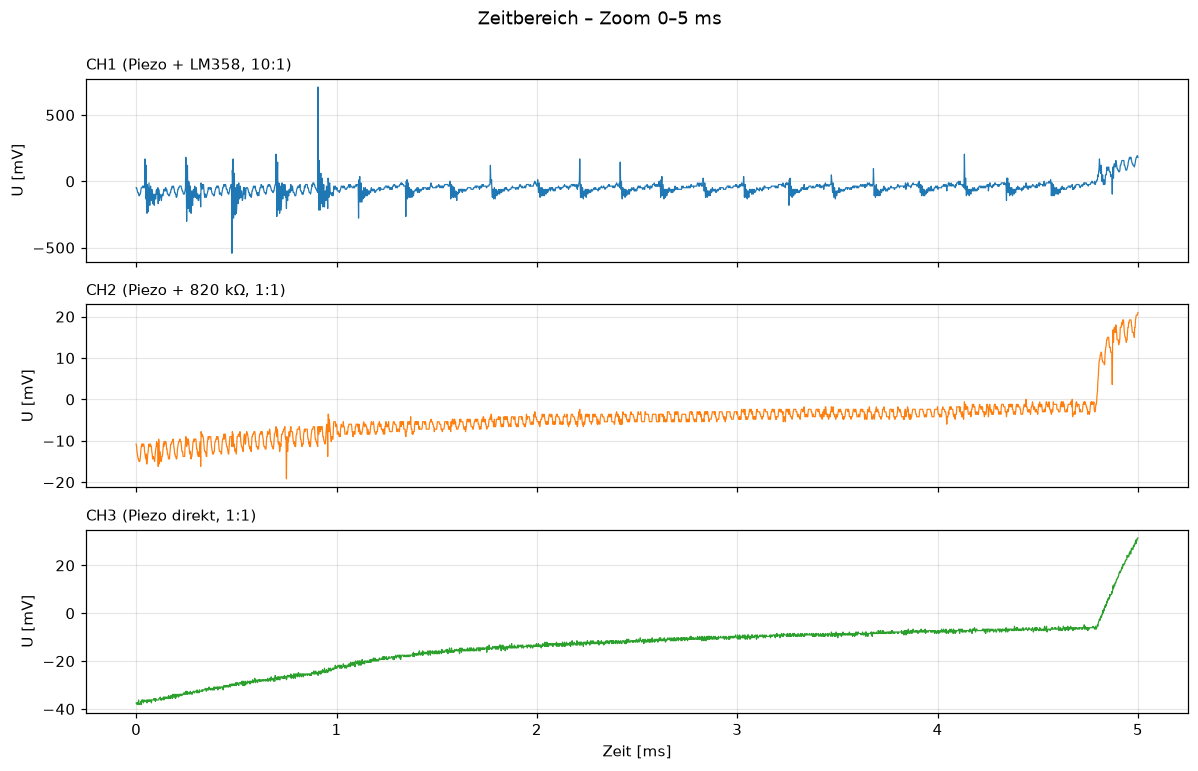

In [4]:
# Zoom to first 5 ms (fine structure)
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, ch in zip(axes, fa.CHANNELS):
    v = channels_data[ch]["captures"][0]
    rate = channels_data[ch]["sample_rate_hz"]
    t = np.arange(len(v)) / rate
    m = t <= 5e-3
    ax.plot(t[m] * 1e3, v[m] * 1e3, color=CHANNEL_COLORS[ch], lw=0.8)
    ax.set_ylabel("U [mV]")
    ax.set_title(CHANNEL_LABELS[ch], loc="left", fontsize=10)
axes[-1].set_xlabel("Time [ms]")
fig.suptitle("Time domain – zoom 0–5 ms", y=0.995)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "timeseries_zoom.png", bbox_inches="tight")
plt.show()

## 4. Power spectral density per channel

Averaged PSD over all 20 captures, logarithmic (dB re V²/Hz), 0–100 kHz.
The shaded band shows ±1 σ across captures — a measure of spectral
repeatability.


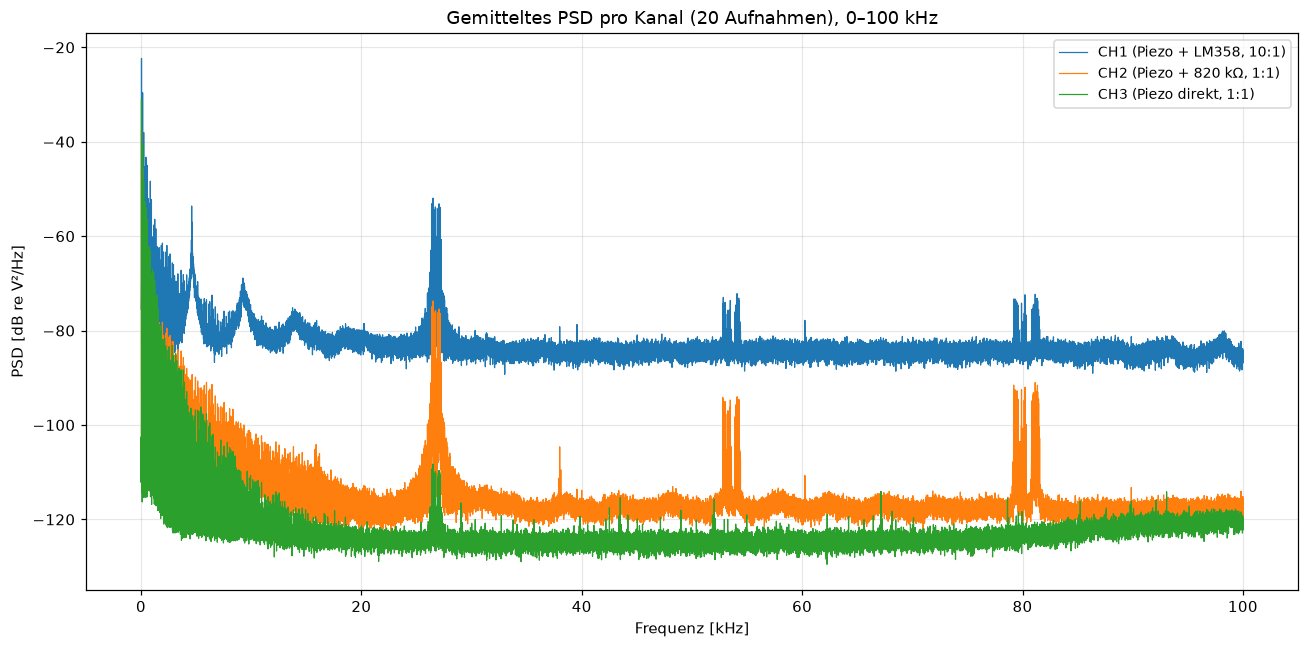

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
for ch in fa.CHANNELS:
    d = channels_data[ch]
    f = d["freqs"]
    m = (f >= 20) & (f <= fa.MAX_FREQUENCY_HZ)
    mean_db = 10 * np.log10(np.maximum(d["mean_psd"][m], 1e-30))
    ax.plot(f[m] / 1e3, mean_db, color=CHANNEL_COLORS[ch], lw=0.8,
            label=CHANNEL_LABELS[ch])
ax.set_xlabel("Frequency [kHz]")
ax.set_ylabel("PSD [dB re V²/Hz]")
ax.set_title("Averaged PSD per channel (20 captures), 0–100 kHz")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "psd_overlay.png", bbox_inches="tight")
plt.show()

## 5. Repeatability per channel

For each individual capture, peaks are detected and clustered across captures.
A peak is considered repeatable if it appears in ≥ 40 % of captures.
Mains frequency (50 Hz) and harmonics are excluded.


In [6]:
for ch in fa.CHANNELS:
    rep = channels_data[ch]["repeatability"]
    items = [(f, i) for f, i in rep.items() if i["repeatable"] and not fa._is_mains(f)]
    items.sort(key=lambda x: x[1]["mean_prominence_db"], reverse=True)
    print(f"\n{CHANNEL_LABELS[ch]} — {len(items)} repeatable peaks (top 8):")
    tab = pd.DataFrame([
        {"f [kHz]": round(f/1e3, 2),
         "Repeatability": f"{i['fraction']:.0%}",
         "Mean prominence [dB]": round(i["mean_prominence_db"], 1)}
        for f, i in items[:8]
    ])
    display(tab)


CH1 (Piezo + LM358, 10:1) — 36 wiederholbare Peaks (Top 8):


,f [kHz],Wiederholbarkeit,mittl. Prominenz [dB]
0,26.94,85%,76.3
1,4.61,100%,66.5
2,54.11,50%,62.7
3,53.04,60%,59.4
4,81.12,55%,59.1
5,26.05,75%,52.4
6,9.30,100%,51.8
7,0.90,100%,50.0



CH2 (Piezo + 820 kΩ, 1:1) — 30 wiederholbare Peaks (Top 8):


,f [kHz],Wiederholbarkeit,mittl. Prominenz [dB]
0,26.97,100%,81.7
1,81.17,50%,77.5
2,54.11,50%,75.4
3,53.04,55%,70.5
4,1.98,100%,63.7
5,0.90,100%,60.1
6,2.91,100%,59.6
7,3.92,100%,56.1



CH3 (Piezo direkt, 1:1) — 27 wiederholbare Peaks (Top 8):


,f [kHz],Wiederholbarkeit,mittl. Prominenz [dB]
0,0.81,100%,69.8
1,26.91,80%,66.0
2,3.03,100%,60.8
3,1.90,100%,59.6
4,3.92,95%,55.4
5,5.07,100%,51.9
6,6.07,100%,51.4
7,7.97,100%,50.4


## 6. Sensor resonances (impulse response)

From the free ring-down of the sensor chain
(`data/impulse_response/...`) the dominant natural resonances of the piezo
are determined. Peaks near these resonances are a property of the sensor,
**not** plant emission.


In [7]:
impulse = fa.load_impulse_spectra(IMPULSE_DIR)
if impulse is not None:
    sensor_resonances = fa.find_impulse_peaks(*impulse)
else:
    sensor_resonances = []
print(f"{len(sensor_resonances)} sensor resonances detected:")
print(", ".join(f"{r/1e3:.1f} kHz" for r in sorted(sensor_resonances)))

15 Sensorresonanzen erkannt:
5.5 kHz, 8.3 kHz, 13.5 kHz, 17.6 kHz, 25.0 kHz, 28.9 kHz, 35.2 kHz, 37.4 kHz, 38.7 kHz, 41.7 kHz, 50.0 kHz, 71.4 kHz, 82.5 kHz, 88.8 kHz, 91.6 kHz


## 7. Cross-channel validation

`cross_channel_validate` applies coherence (±1 kHz, ≥ 2 channels), SNR threshold and
sensor-resonance marking — exactly the same function as in the report.


In [8]:
validated = fa.cross_channel_validate(channels_data, sensor_resonances)
accepted = [p for p in validated if not p["is_sensor_resonance"]]
flagged  = [p for p in validated if p["is_sensor_resonance"]]

def peak_table(peaks):
    return pd.DataFrame([
        {"f [kHz]": round(p["frequency_hz"]/1e3, 2),
         "SNR [dB]": round(p["snr_db"], 1),
         "Repeatability": f"{p['repeatability_fraction']:.0%}",
         "Channels": "+".join(f"CH{c}" for c in sorted(p["channels"]))}
        for p in peaks
    ])

print(f"Criteria passed (no sensor resonance): {len(accepted)}")
display(peak_table(accepted))
print(f"\nMarked as sensor resonance: {len(flagged)}")
display(peak_table(flagged))

Kriterien bestanden (keine Sensorresonanz): 8


,f [kHz],SNR [dB],Wiederholbarkeit,Kanäle
0,0.87,26.7,100%,CH1+CH2+CH3
1,4.15,24.1,100%,CH1+CH2+CH3
2,2.19,23.9,100%,CH1+CH2+CH3
3,26.59,16.8,100%,CH1+CH2+CH3
4,54.11,11.1,50%,CH1+CH2
5,9.55,10.9,100%,CH1+CH2+CH3
6,53.04,9.2,60%,CH1+CH2+CH3
7,81.14,6.9,55%,CH1+CH2



Als Sensorresonanz markiert: 2


,f [kHz],SNR [dB],Wiederholbarkeit,Kanäle
0,14.18,8.3,95%,CH1+CH2+CH3
1,8.25,6.2,100%,CH2+CH3


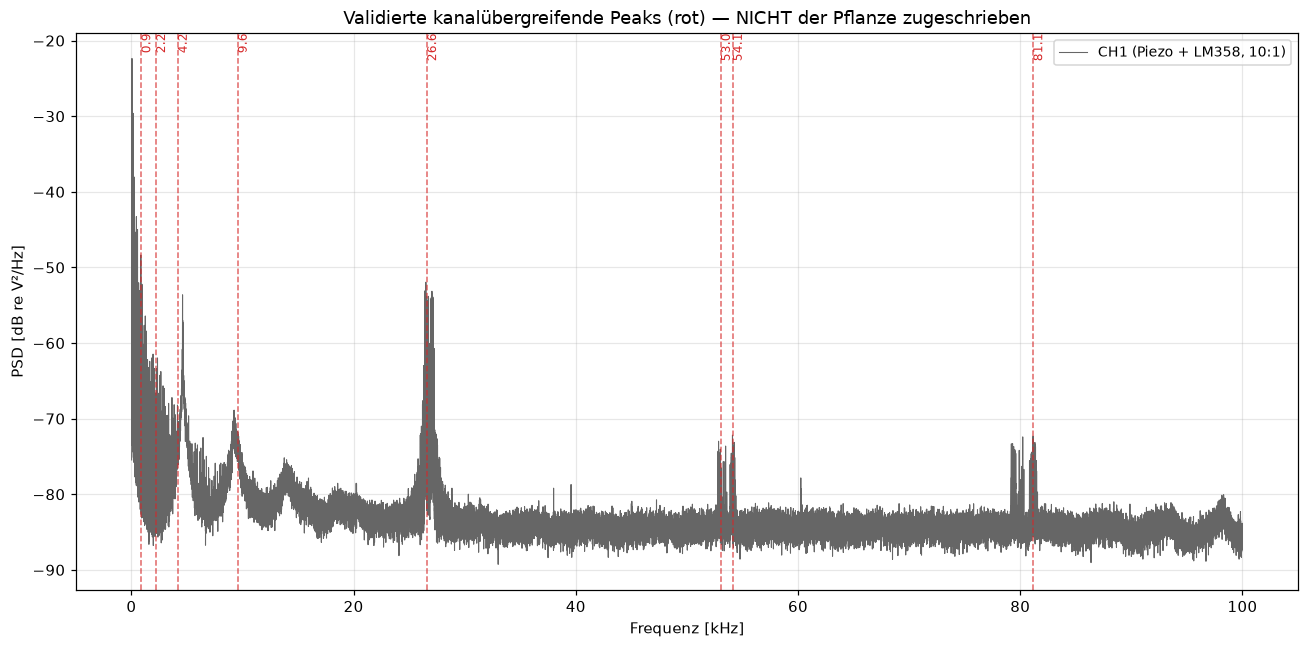

In [9]:
# Mark validated peaks in PSD (CH1 as reference)
fig, ax = plt.subplots(figsize=(12, 6))
d = channels_data[1]
f = d["freqs"]; m = (f >= 20) & (f <= fa.MAX_FREQUENCY_HZ)
ax.plot(f[m]/1e3, 10*np.log10(np.maximum(d["mean_psd"][m], 1e-30)),
        color="0.4", lw=0.7, label=CHANNEL_LABELS[1])
for p in accepted:
    ax.axvline(p["frequency_hz"]/1e3, color="tab:red", ls="--", lw=1, alpha=0.7)
    ax.annotate(f"{p['frequency_hz']/1e3:.1f}", (p["frequency_hz"]/1e3, ax.get_ylim()[1]),
                fontsize=8, color="tab:red", rotation=90, va="top")
ax.set_xlabel("Frequency [kHz]"); ax.set_ylabel("PSD [dB re V²/Hz]")
ax.set_title("Validated cross-channel peaks (red) — NOT attributed to the plant")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validated_peaks_marked.png", bbox_inches="tight")
plt.show()

## 8. Scientific interpretation

**From this passive baseline measurement no peak can be attributed to the plant.**
This is not a deficit of the analysis, but a property of the measurement setup:

- The strongest validated tones (≈ 0.87, 2.19, 4.15 and 26.6 kHz) appear in
  **100 % of all three electrically distinct channels**. Identical, sharp,
  persistent tones on all channels are the signature of
  **common-mode coupling**, not of local plant AE.
  Cross-channel coherence rules out sensor-specific artefacts, but
  **not** common-mode.
- The **morphology does not match**: real cavitation/water-transport AE manifests
  as rare, broadband bursts — not as stationary narrow-band tones.
- Several lines (including ~14.2 and 8.3 kHz; also 71 kHz in the impulse response)
  are identified as **sensor resonances**. The earlier claim of a
  "novel plant signature at 71 kHz" is thereby refuted; the
  "4.3 kHz candidate" is likewise **withdrawn** as common-mode.

**Next scientific step:** a contrast experiment with
*controlled excitation* (defined tap / activity vs. quiet baseline).
Only a differential measurement can separate plant/setup-related emission
from ubiquitous common-mode coupling. This requires physical presence at the setup.

The numbers shown here are reproducibly identical to
`data/reports/frequency_analysis_baseline_20260622/` (shared
implementation in `frequency_analysis.py`).
